# Задание 4.7

Иван и Пётр договорились о встрече в определённом месте между 11 и 12 часами. Каждый приходит и ждёт другого до истечения часа, но не более 15 минут. Найдите вероятности следующих событий:

- $A$ — встреча состоялась;
- $B$ — встреча не состоялась;
- $C$ — Ивану не пришлось ждать Петра;
- $D$ — встреча состоялась после 11 ч 30 мин;
- $E$ — Иван опоздал на встречу;
- $F$ — встреча состоялась, когда до истечения часа оставалось меньше 5 минут.

Постройте график зависимости относительной частоты $\hat p(A)=\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N=150\,000$ и приведите оценку вероятности $\hat p(A)=\dfrac{N_A}{N}$ для $N=150\,000$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** $x$ — момент прихода Ивана, $y$ — Петра (минуты после 11:00), $\Omega=[0,60]^2$, $\mu(\Omega)=3600$, $\ \mathbb P(\cdot)=\mu(\cdot)/3600$.

Каждый ждёт не более 15 минут, а «до истечения часа» не ограничивает ожидание: второй всё равно приходит не позже 12:00. Встреча происходит в момент прихода второго, т.е. в момент $\max(x,y)$.

**$A$ — встреча состоялась:** $|x-y|\le15$. Дополнение — два треугольника с катетом $45$:

$$
\mathbb P(A)=1-\frac{45^2}{60^2}=1-\frac{9}{16}=\frac{7}{16}=0{,}4375 .
$$

**$B=\bar A$:** $\ \mathbb P(B)=\dfrac{9}{16}=0{,}5625$.

**$C$ — Ивану не пришлось ждать Петра.** Понимаем так: когда Иван пришёл, Пётр уже был на месте, т.е. $0\le x-y\le15$ (половина полосы $A$):

$$
\mathbb P(C)=\frac12\,\mathbb P(A)=\frac{7}{32}=0{,}21875 .
$$

**$D$ — встреча состоялась после 11:30:** $|x-y|\le15$ и $\max(x,y)>30$. Из $A$ вычитаем ту часть, которая лежит в квадрате $[0,30]^2$: там площадь полосы равна $30^2-15^2=675$:

$$
\mathbb P(D)=\frac{(3600-2025)-675}{3600}=\frac{900}{3600}=\frac14 .
$$

**$E$ — Иван опоздал на встречу.** Понимаем так: Иван пришёл, когда Пётр уже ушёл, т.е. $x-y>15$ (треугольник с катетом 45):

$$
\mathbb P(E)=\frac{45^2/2}{3600}=\frac{9}{32}=0{,}28125 .
$$

**$F$ — встреча состоялась, когда до конца часа оставалось меньше 5 минут:** $|x-y|\le15$ и $\max(x,y)>55$. В квадрате $[0,55]^2$ площадь полосы $55^2-40^2=1425$:

$$
\mathbb P(F)=\frac{1575-1425}{3600}=\frac{150}{3600}=\frac{1}{24}\approx0{,}041667 .
$$

Проверка: $\mathbb P(A)+\mathbb P(B)=1$; $\ \mathbb P(E)=\frac12\mathbb P(B)$ по симметрии.

**Моделирование:** $N=150\,000$ равномерных точек в квадрате; для каждого события строим $\hat p=N(\cdot)/N$.

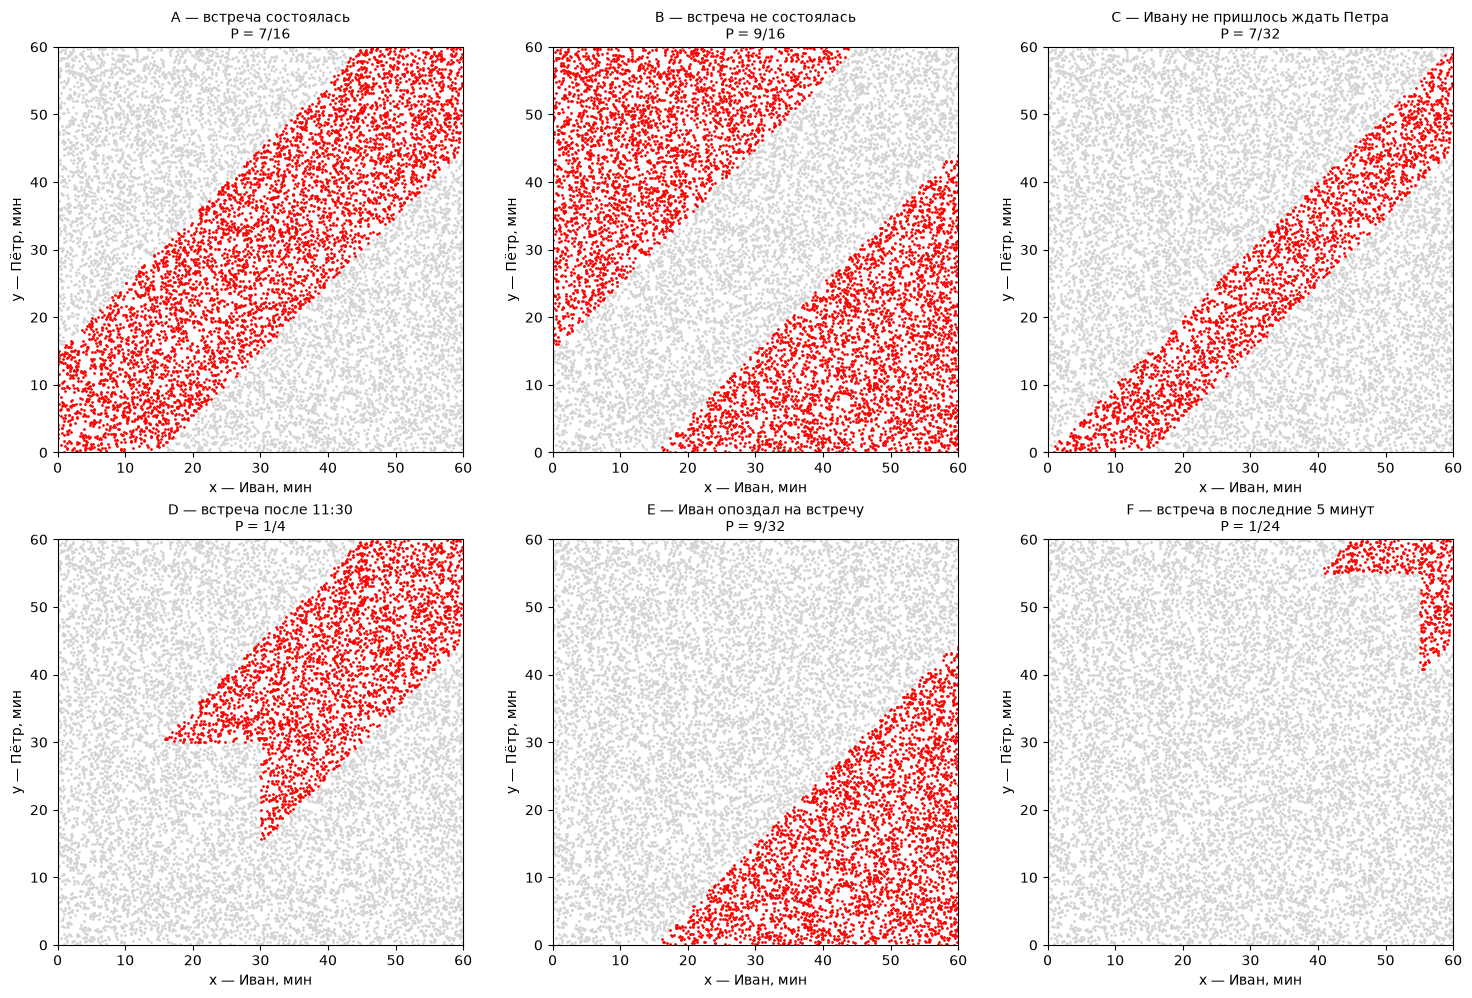

событие                                       P точная   p̂ (N=150 000)    |p̂-P|
A — встреча состоялась                  7/16 = 0.43750          0.43830   8.0e-04
B — встреча не состоялась               9/16 = 0.56250          0.56170   8.0e-04
C — Ивану не пришлось ждать Петра       7/32 = 0.21875          0.22009   1.3e-03
D — встреча после 11:30                  1/4 = 0.25000          0.24868   1.3e-03
E — Иван опоздал на встречу             9/32 = 0.28125          0.27985   1.4e-03
F — встреча в последние 5 минут         1/24 = 0.04167          0.04207   4.1e-04


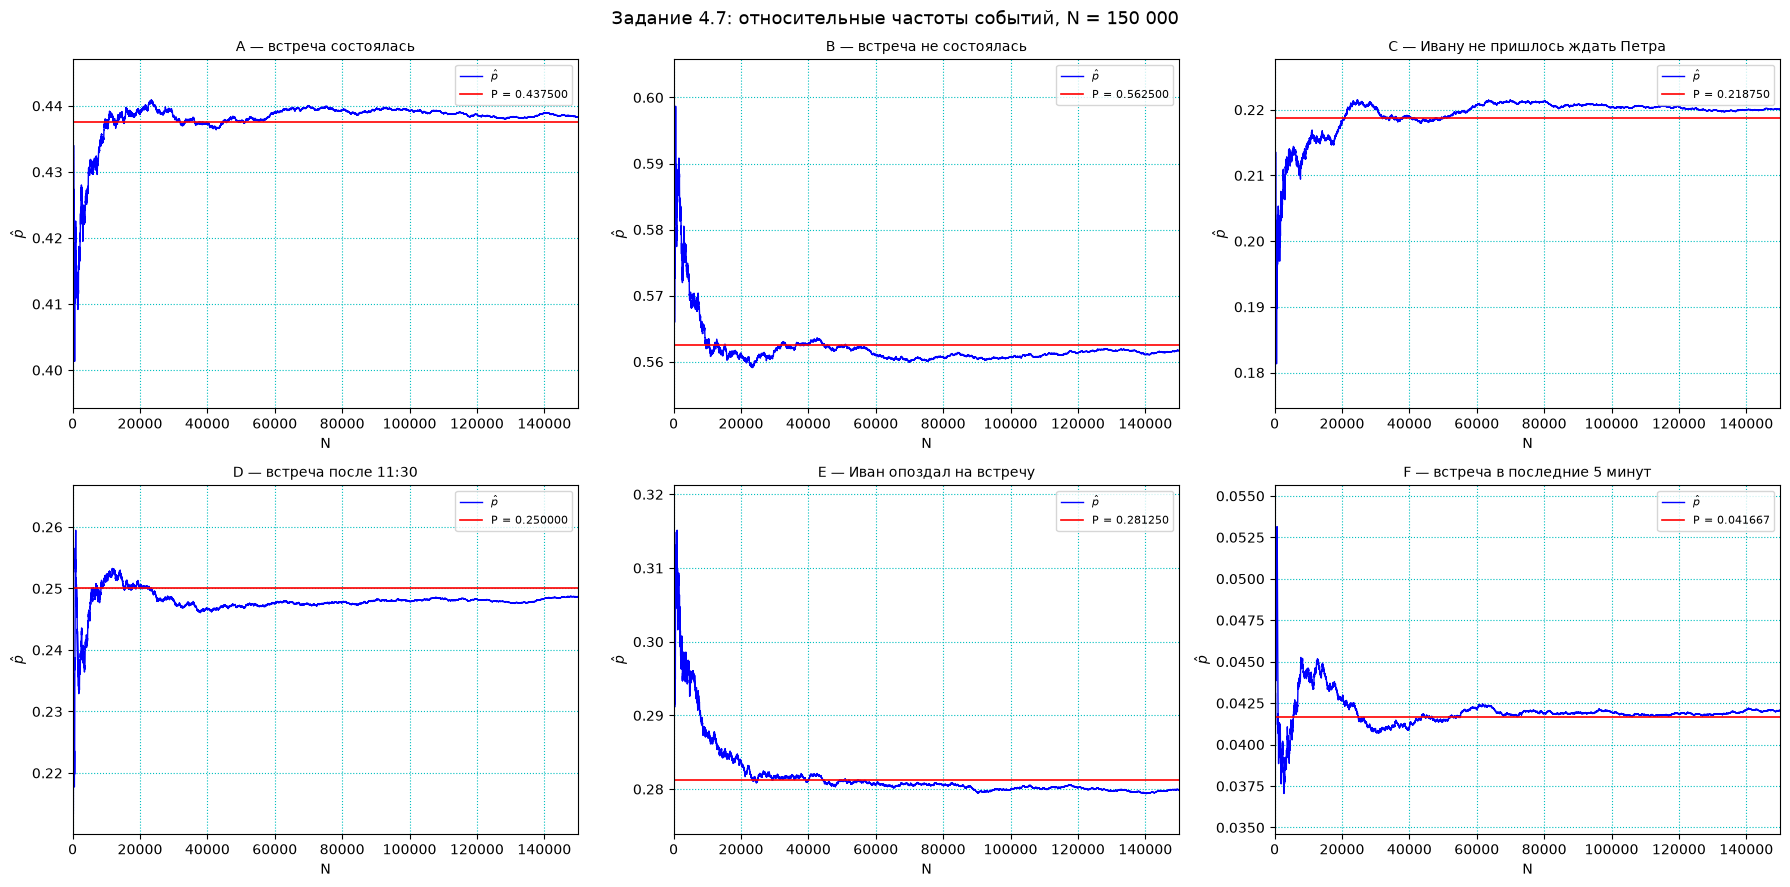

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction as Fr

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


T, w = 60, 15
# ---------- Точные вероятности (отношения площадей) ----------
S_meet = T**2 - (T - w)**2                                       # площадь полосы |x - y| <= 15
band = lambda L: L**2 - max(L - w, 0)**2                         # площадь полосы внутри квадрата [0, L]^2
exact = {
    "A": Fr(S_meet, T**2),
    "B": 1 - Fr(S_meet, T**2),
    "C": Fr(S_meet, 2*T**2),
    "D": Fr(S_meet - band(30), T**2),
    "E": Fr((T - w)**2, 2*T**2),
    "F": Fr(S_meet - band(55), T**2),
}

# ---------- Моделирование ----------
N = 150_000
x = rng.uniform(0, T, N)                     # приход Ивана
y = rng.uniform(0, T, N)                     # приход Петра
meet = np.abs(x - y) <= w
t_meet = np.maximum(x, y)                    # момент встречи — приход второго
hits = {
    "A": meet,
    "B": ~meet,
    "C": (x >= y) & (x - y <= w),            # Пётр уже ждал, когда пришёл Иван
    "D": meet & (t_meet > 30),
    "E": x - y > w,                          # Иван пришёл после ухода Петра
    "F": meet & (t_meet > 55),
}
titles = {"A": "A — встреча состоялась", "B": "B — встреча не состоялась",
          "C": "C — Ивану не пришлось ждать Петра", "D": "D — встреча после 11:30",
          "E": "E — Иван опоздал на встречу", "F": "F — встреча в последние 5 минут"}

# рисунок областей: какие точки (x, y) благоприятны каждому событию
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
s = slice(0, 12_000)
for ax, ev in zip(axes.flat, hits):
    h = hits[ev][s]
    ax.scatter(x[s][~h], y[s][~h], s=1, c="lightgray", rasterized=True)
    ax.scatter(x[s][h], y[s][h], s=1, c="red", rasterized=True)
    ax.set_xlim(0, T); ax.set_ylim(0, T); ax.set_aspect("equal")
    ax.set_title(f"{titles[ev]}\nP = {exact[ev]}", fontsize=10)
    ax.set_xlabel("x — Иван, мин"); ax.set_ylabel("y — Пётр, мин")
fig.tight_layout()
plt.show()

# графики относительных частот
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
print(f"{'событие':<36}{'P точная':>18}{'p̂ (N=150 000)':>17}{'|p̂-P|':>10}")
for ax, ev in zip(axes.flat, hits):
    ph = plot_freq(ax, hits[ev], float(exact[ev]), titles[ev])
    print(f"{titles[ev]:<36}{str(exact[ev]) + ' = ' + format(float(exact[ev]), '.5f'):>18}{ph:>17.5f}{abs(ph - float(exact[ev])):>10.1e}")
fig.suptitle("Задание 4.7: относительные частоты событий, N = 150 000", fontsize=13)
fig.tight_layout()
plt.show()